In [1]:
import flwr as fl
import torch

changed lstm config

In [ ]:
BATCH_SIZE=32
LEARNING_RATE = 0.001	
NUM_EPOCHS = 250
INPUT_SIZE = 9
OUTPUT_SIZE = 1
HIDDEN_SIZE = 64
NUM_LAYERS = 3

WINDOW_LEN = 15
STRIDE = 1 # equal to future window len
FILTER_LEN = 5 

NUM_CLIENTS=10
NUM_ROUNDS=1000
num_epochs=50

In [3]:
import math
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from tqdm import tqdm

from sklearn.metrics import r2_score


import torch
import torch.nn as nn 
from torch.utils.data import Dataset, DataLoader, random_split
import torch.optim as optim
from torch.optim import lr_scheduler

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(DEVICE)

cuda


In [4]:
import pandas as pd

df = pd.read_csv('./../ML-Aided-NR-V2X-QoS-Predictions/dataset.csv')
df.drop(columns='Unnamed: 0', inplace=True)
df.head()

,X,Y,throughput,mcs,distance,pktsize,delay,jitter,sinr,power,dlpathloss,pdr
0,146.601387,368.116530,1.743593,13,184.225706,190,3.242855,0.000000,-1.38581,15,-95.2246,99
1,143.260663,365.862937,1.743592,13,188.238131,190,6.579737,1.241554,-3.11075,15,-95.3060,99
2,137.782258,362.167301,1.743593,13,194.819602,190,3.242855,0.000000,-1.24068,15,-95.5003,99
3,131.346059,357.825556,1.743592,13,202.553954,190,6.579767,1.241449,-3.51258,15,-95.8110,99
4,128.942275,355.120683,1.742541,13,206.124022,190,9.782037,1.008803,-3.02864,15,-96.1639,99


In [5]:
df.drop_duplicates(inplace = True)
df.shape

(8720, 12)

In [6]:
print(df.isnull().sum())

X                0
Y                0
throughput       0
mcs              0
distance       103
pktsize          0
delay            0
jitter        3097
sinr             0
power            0
dlpathloss       0
pdr              0
dtype: int64


In [ ]:
# cols = ['X', 'Y', 'throughput', 'mcs', 'distance', 'pktsize', 'delay', 'jitter', 'pdr']
cols = ['throughput', 'sinr', 'dlpathloss', 'delay']

print(cols)
print(len(cols))
index = cols.index('delay')
print(index)

['X', 'Y', 'throughput', 'mcs', 'distance', 'pktsize', 'delay', 'jitter', 'pdr']
9
6


In [8]:
from sklearn.linear_model import LinearRegression
clean = df[['distance', 'pdr']].dropna()

model = LinearRegression()
model.fit(clean[['pdr']], clean[['distance']])
missing_dist = df['distance'].isnull()
predicted = model.predict(df.loc[missing_dist, ['pdr']])
df.loc[missing_dist, 'distance'] = predicted

In [9]:
clean = df[['jitter', 'delay']].dropna()
model = LinearRegression()
model.fit(clean[['delay']], clean[['jitter']])
missing_jitter = df['jitter'].isnull()
predicted = model.predict(df.loc[missing_jitter, ['delay']])
df.loc[missing_jitter, 'jitter'] = predicted

In [10]:
cols_to_smoothen = ['X', 'Y', 'throughput', 'distance', 'jitter', 'pdr']
for col in cols_to_smoothen:
    df[col] = df[col].rolling(window=FILTER_LEN).mean()

df.bfill(inplace=True)
df.ffill(inplace=True)

df.head(15)

,X,Y,throughput,mcs,distance,pktsize,delay,jitter,sinr,power,dlpathloss,pdr
0,137.586528,361.818601,1.743382,13,195.192283,190,3.242855,0.698361,-1.385810,15,-95.2246,99.0
1,137.586528,361.818601,1.743382,13,195.192283,190,6.579737,0.698361,-3.110750,15,-95.3060,99.0
2,137.586528,361.818601,1.743382,13,195.192283,190,3.242855,0.698361,-1.240680,15,-95.5003,99.0
3,137.586528,361.818601,1.743382,13,195.192283,190,6.579767,0.698361,-3.512580,15,-95.8110,99.0
4,137.586528,361.818601,1.743382,13,195.192283,190,9.782037,0.698361,-3.028640,15,-96.1639,99.0
5,134.540110,358.990050,1.743382,13,199.342416,190,3.242855,0.698361,-2.143690,15,-96.3226,99.0
6,133.130675,357.266206,1.743382,13,201.527131,190,3.274003,0.453668,-2.621170,15,-96.2719,99.0
7,134.205223,357.218623,1.743172,13,200.729762,190,10.528407,0.653647,-3.412130,15,-96.0107,99.0
8,138.371962,359.257770,1.742962,13,196.221081,190,9.782022,0.607124,-3.450500,15,-95.6240,99.0
9,145.258540,363.333656,1.743172,13,188.326038,190,3.242855,0.405363,-1.566280,15,-95.0977,99.0


In [11]:
df.isnull().sum()

X             0
Y             0
throughput    0
mcs           0
distance      0
pktsize       0
delay         0
jitter        0
sinr          0
power         0
dlpathloss    0
pdr           0
dtype: int64

In [12]:
def sliding_window_augmentation(df, cols, index, L = 100, s = 10, add_noise = True, noise_level = 0.02):
    X = df[cols].values
    T, D = X.shape

    n_windows = max(0, (T - L - 1) // s + 1)

    if n_windows <= 0:
        return np.array([]), np.array([])

    windows = np.zeros((n_windows, L, D))
    targets = targets = np.zeros((n_windows, 1))

    col_stds = df[cols].std().values

    for i in range(n_windows):
        start = i * s

        w = X[start : start+L].copy()
        target = X[start+L, index].copy()

        if add_noise:
            noise = np.random.randn(*w.shape) * col_stds * noise_level 
            w += noise
            target_noise = np.random.randn() * col_stds[index] * noise_level
            target += target_noise

        windows[i] = w
        targets[i, 0] = target

    return windows, targets

In [13]:
from torch.utils.data import Dataset, DataLoader

class QosDataset(Dataset):
    def __init__(self, windowed_data, target, feature_index):
        self.X = torch.tensor(windowed_data, dtype=torch.float32)
        self.y = torch.tensor(target, dtype=torch.float32)

    def __len__(self):
        return len(self.X)
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

In [14]:
def create_autoregressive_dataset(data, cols, index, window_len = 100, stride = 10):
    windows, targets = sliding_window_augmentation(
        data, cols, index, L = window_len, s = stride, add_noise=False
    )

    window_noisy, target_noisy = sliding_window_augmentation(
        data, cols, index, L = window_len, s = stride
    )

    if len(windows) > 0 and len(window_noisy) > 0:
        all_windows = np.concatenate([windows, window_noisy], axis=0)
        all_targets = np.concatenate([targets, target_noisy], axis=0)

    elif len(windows) > 0:
        all_windows = windows
        all_targets = targets
    else:
        raise ValueError("No valid windows created")

    print("number of windows ", len(window_noisy))

    dataset = QosDataset(all_windows, all_targets, index)

    return dataset, all_windows, all_targets

In [15]:
dataset, all_windows, all_targets = create_autoregressive_dataset(
    df, cols, index, window_len=WINDOW_LEN, stride=STRIDE
)

number of windows  8705


In [16]:
import numpy as np
from torch.utils.data import DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

def create_federated_data(all_windows, all_targets, index, num_clients, batch_size, train_test_split_ratio = 0.8):
    client_loaders = []

    num_samples = len(all_windows)
    random_indices = np.random.permutation(num_samples)
    shuffled_windows = all_windows[random_indices]
    shuffled_targets = all_targets[random_indices]

    samples_per_client = num_samples // num_clients
    
    for i in range(num_clients):
        start_idx = i * samples_per_client
        end_idx = (i+1) * samples_per_client if i < num_clients -1 else num_samples
        client_windows_partition = shuffled_windows[start_idx : end_idx]
        client_target_partition = shuffled_targets[start_idx : end_idx]

        if len(client_windows_partition) == 0:
            continue

        # train test split
        X_train, X_test, y_train, y_test = train_test_split(
            client_windows_partition, client_target_partition, train_size = train_test_split_ratio, shuffle = True
        )

        # scaling
        scaler = MinMaxScaler()
        n_samples_train, n_timesteps, n_features = X_train.shape
        X_train_reshaped = X_train.reshape(-1, n_features)
        X_train_scaled_reshaped = scaler.fit_transform(X_train_reshaped)
        X_train_scaled = X_train_scaled_reshaped.reshape(n_samples_train, n_timesteps, n_features)

        n_samples_test = X_test.shape[0]
        X_test_reshaped = X_test.reshape(-1, n_features)
        X_test_scaled_reshaped = scaler.transform(X_test_reshaped)
        X_test_scaled = X_test_scaled_reshaped.reshape(n_samples_test, n_timesteps, n_features)

        target_scaler = MinMaxScaler()
        y_train_scaled = target_scaler.fit_transform(y_train)
        y_test_scaled = target_scaler.transform(y_test)

        # dataloaders
        train_dataset = QosDataset(X_train_scaled, y_train_scaled, index)
        test_dataset = QosDataset(X_test_scaled, y_test_scaled, index)

        train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
        test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

        client_loaders.append({
            'train': train_loader,
            'test' : test_loader,
            'target_scaler': target_scaler
        })

    return client_loaders

In [17]:
client_loaders = create_federated_data(
    all_windows=all_windows,
    all_targets=all_targets,
    index = index,
    num_clients=NUM_CLIENTS,
    batch_size = BATCH_SIZE
)

In [18]:
# global_test_loader = client_loaders[int(cid)]["train"]
global_test_loader = client_loaders[0]["test"]
global_target_scaler = client_loaders[0]["target_scaler"]

In [19]:
from typing import Dict, List, Optional, Tuple
from collections import OrderedDict

def get_parameters(model) -> List[np.ndarray]:
    return [val.cpu().numpy() for _, val in model.state_dict().items()]

def set_parameters(model, parameters : List[np.ndarray]):
    param_dict = zip(model.state_dict().keys(), parameters)
    state_dict = OrderedDict({k : torch.from_numpy(v) for k, v in param_dict})
    model.load_state_dict(state_dict, strict=True)

In [20]:
class LSTM(nn.Module):
    def __init__(self, input_size=12, output_size=100, hidden_size=50, num_layers=3, dropout=0.3, bidirectional=True):
        super(LSTM, self).__init__()
        self.input_size = input_size
        self.output_size = output_size
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.bidirectional = bidirectional

        self.lstm = nn.LSTM(
            input_size, 
            hidden_size, 
            num_layers, 
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0,
            bidirectional=bidirectional
        )

        direction_factor = 2 if bidirectional else 1
        self.fc = nn.Sequential(
            nn.Linear(hidden_size * direction_factor, 128),
            nn.ReLU(),
            nn.Linear(128, output_size)
        )

    def forward(self, x):
        h0 = torch.zeros(self.num_layers * (2 if self.bidirectional else 1), x.size(0), self.hidden_size).to(x.device)
        c0 = torch.zeros(self.num_layers * (2 if self.bidirectional else 1), x.size(0), self.hidden_size).to(x.device)

        out, _ = self.lstm(x, (h0, c0))
        out = out[:, -1, :]  # take the last time step
        out = self.fc(out)
        return out

In [ ]:
def train(model, trainloader, criterion, optimizer, epochs, scheduler=None):
    model.train()
    
    for epoch in range(epochs):
        epoch_loss = 0
        for X, y in trainloader:
            model.to(DEVICE)
            X, y = X.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad()
            pred = model(X)
            loss = criterion(pred, y)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()

        if scheduler is not None:
            scheduler.step()
    
    avg_loss = epoch_loss / len(trainloader)
    
    return avg_loss

In [22]:
from sklearn.metrics import r2_score
import torch 

def validate(model, valloader, criterion, epoch, target_scaler):
    model.eval()
    epoch_loss = 0
    all_preds_unscaled = []
    all_targets_unscaled = []

    with torch.no_grad():
        for X, y in valloader:
            X, y = X.to(DEVICE), y.to(DEVICE)
            pred = model(X)
            loss = criterion(pred.squeeze(), y.squeeze())
            epoch_loss += loss.item()

            pred_unscaled = target_scaler.inverse_transform(pred.cpu().numpy().reshape(-1,1))
            y_unscaled = target_scaler.inverse_transform(y.cpu().numpy().reshape(-1,1))

            all_preds_unscaled.append(pred_unscaled)
            all_targets_unscaled.append(y_unscaled)

    avg_loss = epoch_loss / len(valloader)

    final_preds = np.concatenate(all_preds_unscaled)
    final_targets = np.concatenate(all_targets_unscaled)

    r2 = r2_score(final_targets, final_preds)

    if (epoch + 1) % 1000 == 0:
        print(f"Epoch {epoch+1}: Val Loss = {avg_loss:.4f}, R2 = {r2:.4f}")

    return avg_loss, r2

In [23]:
import flwr as fl
import torch
import torch.optim as optim
import numpy as np
import pandas as pd
import os
import time # Required for the file lock
from sklearn.preprocessing import MinMaxScaler

class QosClient(fl.client.NumPyClient):
    def __init__(self, cid, model, trainloader, testloader, target_scaler):
        self.cid = cid
        self.model = model.to(DEVICE)
        self.trainloader = trainloader
        self.testloader = testloader
        self.target_scaler = target_scaler
        self.criterion = torch.nn.MSELoss()
        self.optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

        # csv logging
        log_dir = "../results/" 
        self.log_file_path = os.path.join(log_dir, "training_log.csv")
        self.lock_file_path = os.path.join(log_dir, "training_log.csv.lock")
        self._initialize_log_file()

    def _initialize_log_file(self):
        """Creates the log file with headers if it doesn't exist."""
        self._acquire_lock()
        try:
            if not os.path.exists(self.log_file_path):
                # We will log metrics that are available during the 'evaluate' phase
                df = pd.DataFrame(columns=["round", "client_id", "val_loss", "r2_score"])
                df.to_csv(self.log_file_path, index=False)
        finally:
            self._release_lock()

    def _acquire_lock(self):
        """Acquires a file-based lock, waiting if necessary."""
        while os.path.exists(self.lock_file_path):
            time.sleep(0.1)
        open(self.lock_file_path, 'w').close()

    def _release_lock(self):
        """Releases the file-based lock."""
        if os.path.exists(self.lock_file_path):
            os.remove(self.lock_file_path)

    def get_parameters(self, config):
        """Returns the model parameters."""
        print(f"[Client {self.cid}] get_parameters")
        return get_parameters(self.model)

    def fit(self, parameters, config):
        """Trains the model on the local dataset."""
        server_round = config["server_round"]
        local_epochs = config["local_epochs"]
        print(f"[Client {self.cid}, round {server_round}] fit, config: {config}")

        set_parameters(self.model, parameters)
        # Assuming your train function returns the average loss
        avg_train_loss = train(self.model, self.trainloader, self.criterion, self.optimizer, local_epochs)

        # Return metrics to the server for aggregation
        return get_parameters(self.model), len(self.trainloader.dataset), {"train_loss": avg_train_loss}

    def evaluate(self, parameters, config):
        """Evaluates the model on the local test set and logs the results."""
        server_round = config["server_round"]
        print(f"[Client {self.cid}, round {server_round}] evaluate")

        set_parameters(self.model, parameters)

        # Get validation loss and R2 score from your validate function
        val_loss, r2 = validate(self.model, self.testloader, self.criterion, -1, self.target_scaler)
        print(f"Client {self.cid} Test Loss: {val_loss:.4f}, R² Score: {r2:.4f}")

        self._log_metrics_to_csv(server_round, val_loss, r2)

        # Return results to the server
        return float(val_loss), len(self.testloader.dataset), {"r2_score": float(r2)}

    def _log_metrics_to_csv(self, server_round, val_loss, r2_score):
        """Appends a new row of metrics to the central log file."""
        self._acquire_lock()
        try:
            new_row = pd.DataFrame({
                "round": [server_round],
                "client_id": [self.cid],
                "val_loss": [val_loss],
                "r2_score": [r2_score]
            })
            new_row.to_csv(self.log_file_path, mode='a', header=False, index=False)
        finally:
            self._release_lock()

In [24]:
def client_fn(cid) -> QosClient:
    model = LSTM(input_size=INPUT_SIZE, output_size=OUTPUT_SIZE, hidden_size=HIDDEN_SIZE, num_layers=NUM_LAYERS).to(DEVICE)
    trainloader = client_loaders[int(cid)]["train"]
    testloader = client_loaders[int(cid)]["test"]
    scaler = client_loaders[int(cid)]["target_scaler"]
    client = QosClient(cid, model, trainloader, testloader, scaler)
    # return client.to_client()
    return client

In [25]:
model = LSTM(input_size=INPUT_SIZE, output_size=OUTPUT_SIZE, hidden_size=HIDDEN_SIZE, num_layers=NUM_LAYERS).to(DEVICE)
# model.to(DEVICE)
params = get_parameters(model)
del model

In [26]:
from typing import Dict, List, Optional, Tuple

def evaluate(server_round : int, params : fl.common.NDArrays, config: Dict[str, fl.common.Scalar]) -> Optional[Tuple[float, Dict[str, fl.common.Scalar]]]:
    model = LSTM(input_size=INPUT_SIZE, output_size=OUTPUT_SIZE, hidden_size=HIDDEN_SIZE, num_layers=NUM_LAYERS).to(DEVICE)
    set_parameters(model, params)
    criterion = torch.nn.MSELoss()
    # model, valloader, criterion, epoch, target_scaler
    loss, r2 = validate(model, global_test_loader, criterion, -1, global_target_scaler)
    print(f"Server-side R2 score is {r2} and validation loss is {loss}")
    return loss,{"R2": r2}

In [27]:
def fit_config(server_round: int):
    config = {
        "server_round": server_round,  
        "local_epochs": NUM_EPOCHS
    }
    return config

In [28]:
strategy = fl.server.strategy.FedAvg(
    fraction_fit=0.7,
    fraction_evaluate=1,
    min_fit_clients=7,
    min_evaluate_clients=NUM_CLIENTS,
    min_available_clients=NUM_CLIENTS,
    initial_parameters=fl.common.ndarrays_to_parameters(params),
    evaluate_fn=evaluate,
    on_fit_config_fn=fit_config,
    on_evaluate_config_fn=fit_config
)

In [29]:
client_resources = {"num_cpus":1,"num_gpus":1}

In [30]:
Output_History=fl.simulation.start_simulation(
    client_fn=client_fn,
    num_clients=NUM_CLIENTS,
    config=fl.server.ServerConfig(num_rounds=NUM_ROUNDS),
    strategy=strategy,
    client_resources=client_resources
)

	Instead, use the `flwr run` CLI command to start a local simulation in your Flower app, as shown for example below:

		$ flwr new  # Create a new Flower app from a template

		$ flwr run  # Run the Flower app in Simulation Mode

	Using `start_simulation()` is deprecated.

            This is a deprecated feature. It will be removed
            entirely in future versions of Flower.
        
INFO :      Starting Flower simulation, config: num_rounds=1000, no round_timeout
2025-08-28 15:15:59,660	INFO worker.py:1771 -- Started a local Ray instance.
INFO :      Flower VCE: Ray initialized with resources: {'accelerator_type:G': 1.0, 'node:__internal_head__': 1.0, 'CPU': 16.0, 'object_store_memory': 2240879001.0, 'memory': 4481758004.0, 'GPU': 1.0, 'node:192.168.49.157': 1.0}
INFO :      Optimize your simulation with Flower VCE: https://flower.ai/docs/framework/how-to-run-simulations.html
INFO :      Flower VCE: Resources for each Virtual Client: {'num_cpus': 1, 'num_gpus': 1}
INFO :      

Epoch 0: Val Loss = 0.0292, R2 = -0.0525
Server-side R2 score is -0.052481770515441895 and validation loss is 0.029169573956592518


(ClientAppActor pid=10388) WARNING :   DEPRECATED FEATURE: `client_fn` now expects a signature `def client_fn(context: Context)`.The provided `client_fn` has signature: {'cid': <Parameter "cid">}. You can import the `Context` like this: `from flwr.common import Context`
(ClientAppActor pid=10388) 
(ClientAppActor pid=10388)             This is a deprecated feature. It will be removed
(ClientAppActor pid=10388)             entirely in future versions of Flower.
(ClientAppActor pid=10388)         
(ClientAppActor pid=10388) WARNING :   Deprecation Warning: The `client_fn` function must return an instance of `Client`, but an instance of `NumpyClient` was returned. Please use `NumPyClient.to_client()` method to convert it to `Client`.


(ClientAppActor pid=10388) [Client 6, round 1] fit, config: {'server_round': 1, 'local_epochs': 5000}


(ClientAppActor pid=10388) WARNING :   DEPRECATED FEATURE: `client_fn` now expects a signature `def client_fn(context: Context)`.The provided `client_fn` has signature: {'cid': <Parameter "cid">}. You can import the `Context` like this: `from flwr.common import Context`
(ClientAppActor pid=10388) 
(ClientAppActor pid=10388)             This is a deprecated feature. It will be removed
(ClientAppActor pid=10388)             entirely in future versions of Flower.
(ClientAppActor pid=10388)         
(ClientAppActor pid=10388) WARNING :   Deprecation Warning: The `client_fn` function must return an instance of `Client`, but an instance of `NumpyClient` was returned. Please use `NumPyClient.to_client()` method to convert it to `Client`.


...

(ClientAppActor pid=10388) WARNING :   DEPRECATED FEATURE: `client_fn` now expects a signature `def client_fn(context: Context)`.The provided `client_fn` has signature: {'cid': <Parameter "cid">}. You can import the `Context` like this: `from flwr.common import Context`
(ClientAppActor pid=10388) 
(ClientAppActor pid=10388)             This is a deprecated feature. It will be removed
(ClientAppActor pid=10388)             entirely in future versions of Flower.
(ClientAppActor pid=10388)         
(ClientAppActor pid=10388) WARNING :   Deprecation Warning: The `client_fn` function must return an instance of `Client`, but an instance of `NumpyClient` was returned. Please use `NumPyClient.to_client()` method to convert it to `Client`.
(ClientAppActor pid=10388) WARNING :   DEPRECATED FEATURE: `client_fn` now expects a signature `def client_fn(context: Context)`.The provided `client_fn` has signature: {'cid': <Parameter "cid">}. You can import the `Context` like this: `from flwr.common impo

(ClientAppActor pid=10388) [Client 1, round 1000] evaluate
(ClientAppActor pid=10388) Epoch 0: Val Loss = 0.0247, R2 = 0.3068
(ClientAppActor pid=10388) Client 1 Test Loss: 0.0247, R² Score: 0.3068
(ClientAppActor pid=10388) [Client 2, round 1000] evaluate
(ClientAppActor pid=10388) Epoch 0: Val Loss = 0.0145, R2 = 0.3642
(ClientAppActor pid=10388) Client 2 Test Loss: 0.0145, R² Score: 0.3642
(ClientAppActor pid=10388) [Client 3, round 1000] evaluate
(ClientAppActor pid=10388) Epoch 0: Val Loss = 0.0258, R2 = 0.2822
(ClientAppActor pid=10388) Client 3 Test Loss: 0.0258, R² Score: 0.2822
(ClientAppActor pid=10388) [Client 5, round 1000] evaluate
(ClientAppActor pid=10388) Epoch 0: Val Loss = 0.0132, R2 = 0.2843
(ClientAppActor pid=10388) Client 5 Test Loss: 0.0132, R² Score: 0.2843
(ClientAppActor pid=10388) [Client 7, round 1000] evaluate


INFO :      		round 70: 0.019864522823693484
INFO :      		round 71: 0.019683540407674047
INFO :      		round 72: 0.019200940874923782
INFO :      		round 73: 0.01978192923415918
INFO :      		round 74: 0.020622501649036583
INFO :      		round 75: 0.019927636403008365
INFO :      		round 76: 0.019624724876220252
INFO :      		round 77: 0.01961104713793082
INFO :      		round 78: 0.01986489742279942
(ClientAppActor pid=10388) WARNING :   DEPRECATED FEATURE: `client_fn` now expects a signature `def client_fn(context: Context)`.The provided `client_fn` has signature: {'cid': <Parameter "cid">}. You can import the `Context` like this: `from flwr.common import Context`INFO :      		round 79: 0.019385504016430456

(ClientAppActor pid=10388) 
(ClientAppActor pid=10388)             This is a deprecated feature. It will be removed
(ClientAppActor pid=10388)             entirely in future versions of Flower.
(ClientAppActor pid=10388)         
(ClientAppActor pid=10388) WARNING :   Deprecation W

(ClientAppActor pid=10388) Epoch 0: Val Loss = 0.0187, R2 = 0.1762
(ClientAppActor pid=10388) Client 7 Test Loss: 0.0187, R² Score: 0.1762
(ClientAppActor pid=10388) [Client 9, round 1000] evaluate
(ClientAppActor pid=10388) Epoch 0: Val Loss = 0.0225, R2 = 0.3043
(ClientAppActor pid=10388) Client 9 Test Loss: 0.0225, R² Score: 0.3043


INFO :      		round 969: 0.017598424660338258
INFO :      		round 970: 0.017732618320521646
INFO :      		round 971: 0.017195031593887095
INFO :      		round 972: 0.01676068962181241
INFO :      		round 973: 0.017257024654166096
INFO :      		round 974: 0.018293752588876735
INFO :      		round 975: 0.017606881000260314
INFO :      		round 976: 0.017748958902004897
INFO :      		round 977: 0.01629286897157065
INFO :      		round 978: 0.018341015395443798
INFO :      		round 979: 0.01840069803266405
INFO :      		round 980: 0.017204966567541388
INFO :      		round 981: 0.017997364566756668
INFO :      		round 982: 0.017536207086099733
INFO :      		round 983: 0.01645197051349731
INFO :      		round 984: 0.01657142978061033
INFO :      		round 985: 0.018509181985494002
INFO :      		round 986: 0.017269406301255168
INFO :      		round 987: 0.01756521534275221
INFO :      		round 988: 0.017059516948806544
INFO :      		round 989: 0.016214029484333217
INFO :      		round 990: 0.0158944258265

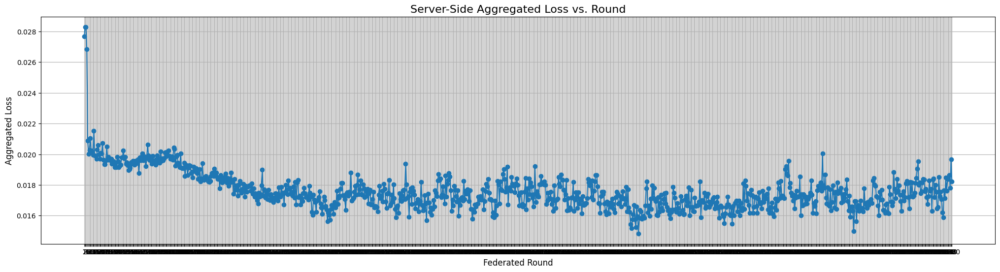

In [31]:
import matplotlib.pyplot as plt

# Assume 'Output_History' is your captured Flower History object

# Extract the round numbers and aggregated loss values
rounds = [rnd for rnd, _ in Output_History.losses_distributed]
losses = [loss for _, loss in Output_History.losses_distributed]

# Create the plot
plt.figure(figsize=(25, 6))
plt.plot(rounds, losses, marker='o', linestyle='-')
plt.title("Server-Side Aggregated Loss vs. Round", fontsize=16)
plt.xlabel("Federated Round", fontsize=12)
plt.ylabel("Aggregated Loss", fontsize=12)
plt.grid(True)
plt.xticks(rounds)

# --- Add this line to save the figure ---
plt.savefig("../results/server_loss_plot.png")

# Display the plot
plt.show()

In [32]:
r2_history = Output_History.metrics_centralized['R2']

best_round_data = max(r2_history, key=lambda item: item[1])

best_round = best_round_data[0]
max_r2_score = best_round_data[1]

print(f"Maximum server-side R2 score: {max_r2_score:.4f}")
print(f"This occurred at round: {best_round}")

Maximum server-side R2 score: 0.4781
This occurred at round: 677
